In [36]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
# Import Exponential Smoothing models from statsmodels
from statsmodels.tsa.holtwinters import (
    ExponentialSmoothing,
    Holt,
    SimpleExpSmoothing,
)

# Import Auto-ARIMA from pmdarima
from pmdarima.arima import auto_arima

import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
import warnings
warnings.filterwarnings('ignore')

In [37]:
df = pd.read_csv('AusGas.csv')
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month',inplace=True)
df.index.freq = "MS"
df

,GasProd
Month,
1956-01-01,1709
1956-02-01,1646
1956-03-01,1794
1956-04-01,1878
1956-05-01,2173
...,...
1995-04-01,49013
1995-05-01,56624
1995-06-01,61739


In [29]:
y_train = df['GasProd'][:-12]
y_test = df['GasProd'][-12:]

<Axes: xlabel='Month'>

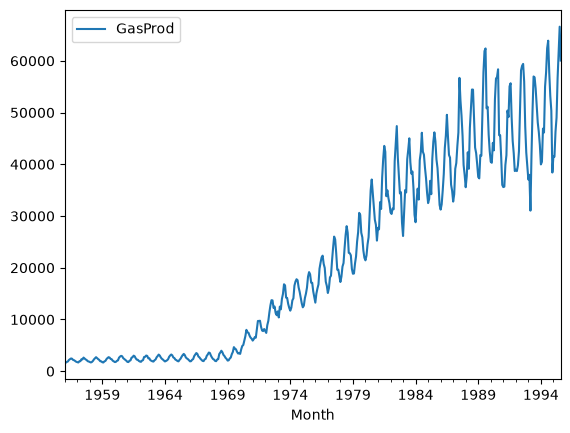

In [24]:
df.plot()

In [46]:
y_train_df = pd.DataFrame(y_train)
y_train_df

,GasProd
Month,
1956-01-01,1709
1956-02-01,1646
1956-03-01,1794
1956-04-01,1878
1956-05-01,2173
...,...
1994-04-01,46147
1994-05-01,55011
1994-06-01,57799


# Simple Exp Smoothing

In [47]:
alpha = np.linspace(0.01, 0.99, 20)
scores = []
for a in tqdm(alpha):
    ses =SimpleExpSmoothing(y_train)
    fit1=ses.fit(smoothing_level=a)
    fcast1 = fit1.forecast(len(y_test)) 
    rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
    scores.append([a, rms])
df_scores = pd.DataFrame(scores, columns=['alpha', 'score'])
df_scores.sort_values('score')    

  0%|          | 0/20 [00:00<?, ?it/s]


TypeError: initialization_method must be a string

In [42]:
alpha=0.113158
ses =SimpleExpSmoothing(y_train)
fit1=ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test)) 
rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
y_train.plot(color='pink',label ='Train')
y_test.plot(color='blue',label ='Test')
fcast1.plot(color='purple',label='Forecast')
rms= np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,40000,f"RMSE {rms}")


TypeError: initialization_method must be a string

# Holts smothing

In [43]:

alpha, beta = np.linspace(0.01, 0.99, 20), np.linspace(0.01, 0.99, 20)
scores = []
for a in tqdm(alpha):
  for b in beta:
      for e in [True, False]:
                holt =Holt(y_train_df, exponential=e)
                fit1 = holt.fit(smoothing_level=a, smoothing_trend=b, optimized=False)
                fcast1 = fit1.forecast(len(y_test)) 
                rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
                scores.append([a, b,e, rms])
df_scores = pd.DataFrame(scores, columns=['alpha', 'beta','exponential', 'score'])
df_scores.sort_values('score')    

  0%|          | 0/20 [00:00<?, ?it/s]


TypeError: initialization_method must be a string

# Holts exponential smoothing

In [ ]:

alpha, beta = np.linspace(0.01, 0.99, 10), np.linspace(0.01, 0.99, 10)
gamma = np.linspace(0.01, 0.99, 10)
scores = []
seasonality = ['add','mul']
for a in tqdm(alpha):
  for b in beta:
    for g in gamma:
        for s in seasonality:
            hw_add = ExponentialSmoothing(
            y_train_df, 
            seasonal_periods=12, 
            trend='add', 
            seasonal=s
           )
            fit1 = hw_add.fit(smoothing_level=a, smoothing_trend=b, smoothing_seasonal=g)
            fcast1 = fit1.forecast(len(y_test)) 
            rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
            scores.append([a, b, g,s, rms])
df_scores = pd.DataFrame(scores, columns=['alpha', 'beta', 'gamma','seasonal', 'score'])
df_scores.sort_values('score')    



# Exponentital smoothing

In [12]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [15]:
hw_model = ExponentialSmoothing(y_train_df , trend = 'add', seasonal = 'mul' , seasonal_periods = 12).fit()

hw_pred = hw_model.forecast(12)

hw_rmse = root_mean_squared_error(y_test, hw_pred)
print(f"Holt-Winters RMSE: {hw_rmse:.2f}")

Holt-Winters RMSE: 2426.33


# Auto ARIMA

In [30]:
from pmdarima.arima import auto_arima

In [31]:
model = auto_arima(y_train , trace=True, error_action = 'ignore', suppress_warnings = True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8355.115, Time=1.18 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8632.352, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8589.946, Time=0.07 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8603.593, Time=0.09 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8631.502, Time=0.03 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=8571.932, Time=0.56 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=8577.053, Time=0.18 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=8326.858, Time=1.29 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=8426.132, Time=1.04 sec
 ARIMA(4,1,2)(0,0,0)[0] intercept   : AIC=8270.030, Time=2.00 sec
 ARIMA(4,1,1)(0,0,0)[0] intercept   : AIC=8404.137, Time=1.72 sec
 ARIMA(5,1,2)(0,0,0)[0] intercept   : AIC=8391.024, Time=2.31 sec
 ARIMA(4,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.61 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.91 sec
 ARIMA(5,1,1)(0,0,0)[0] intercept   : AIC=8

In [32]:
forecast = model.predict(n_periods = len(y_test))
forecast = pd.DataFrame(forecast , index = y_test.index ,columns = ['Prediction'])
rms = root_mean_squared_error(y_test , forecast)
rms

2575.9887175814033

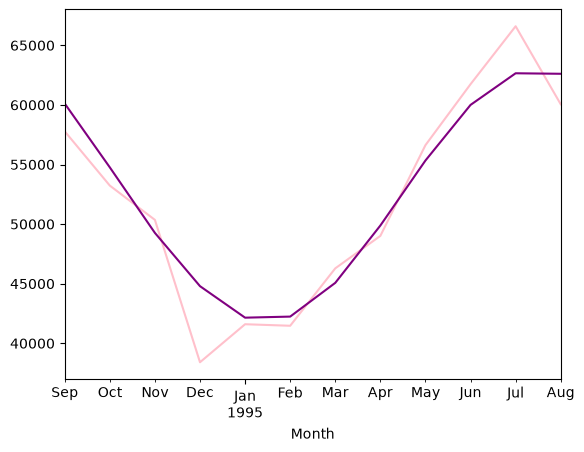

In [33]:
y_test.plot(color = 'pink')
forecast["Prediction"].plot(color = 'purple')
plt.show()

# SARIMA

In [34]:
 

model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)

forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
rmse = root_mean_squared_error(y_test, forecast)
print('y_test RMSE: %.3f' % rmse)



Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=3.34 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=8632.352, Time=0.04 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=8255.565, Time=1.09 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=8438.509, Time=0.98 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=8631.502, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=8589.946, Time=0.05 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=3.18 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=8170.931, Time=2.70 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=8438.053, Time=0.72 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=8218.685, Time=4.99 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=8204.884, Time=5.24 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=8371.138, Time=2.47 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=7.14 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=8219.426, Time=1.56 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept

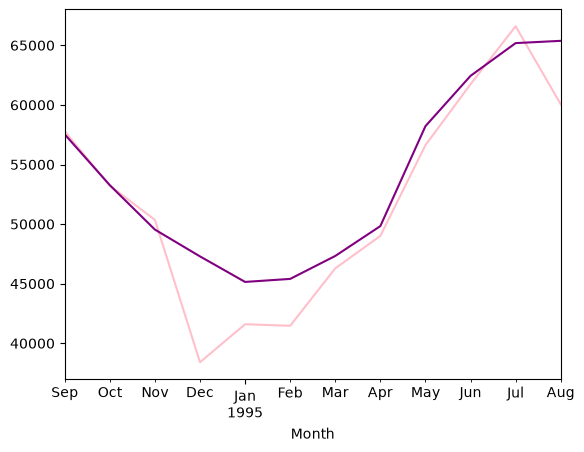

In [35]:
y_test.plot(color = 'pink')
forecast["Prediction"].plot(color = 'purple')
plt.show()

In [38]:
from pmdarima.pipeline import Pipeline
from pmdarima.preprocessing import BoxCoxEndogTransformer
import pmdarima as pm

In [39]:
pipeline = Pipeline([
    ("boxcox", BoxCoxEndogTransformer()),
    ('model',pm.AutoARIMA(seasonal=True , suppress_warnings=True, m=12))
])
pipeline.fit(y_train)

,steps,"[('boxcox', ...), ('model', ...)]"
Name,Type,Value
n_samples_,int,464
steps_,list,"[('boxcox', BoxCoxEndogTransformer()), ('model', AutoARIMA(m=12))]"
x_feats_,NoneType,None


In [40]:
forecast = pipeline.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
rmse = root_mean_squared_error(y_test, forecast)
print('y_test RMSE: %.3f' % rmse)

y_test RMSE: 3593.527
